# 01. Подготовка данных

Вариант 05. Одна строка исходной выгрузки соответствует одному объявлению об аренде.
Целевая переменная – месячная арендная плата `rent_rub` в рублях.

## Пути проекта

Исходные файлы лежат в `data/raw/`. Корень проекта определяем из рабочего каталога ядра, чтобы запуск из `notebooks/` тоже находил пакет `modules`.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "modules").is_dir():
    raise RuntimeError("Запустите ноутбук из корня проекта или папки notebooks/.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"


## Загрузка и проверка формата CSV

Как в первой лабораторной и практикуме 2, сначала читаем пять строк через `pd.read_csv`. Проверяем кодировку, разделитель полей и десятичный знак по названиям районов, площади и заголовкам.

In [2]:
import pandas as pd

RAW_CSV_PATH = RAW_DATA_DIR / "rent_v05.csv"
CSV_ENCODING = "utf-8"
CSV_SEPARATOR = ","
CSV_DECIMAL = "."

sample = pd.read_csv(
    RAW_CSV_PATH,
    encoding=CSV_ENCODING,
    sep=CSV_SEPARATOR,
    decimal=CSV_DECIMAL,
    nrows=5,
)

assert pd.api.types.is_numeric_dtype(sample["total_area"]), "Площадь не прочиталась как число."

print(f"Кодировка – {CSV_ENCODING.upper()}")
print(f"Разделитель полей – {CSV_SEPARATOR!r}, десятичный знак – {CSV_DECIMAL!r}")
print(f"Пример категории – {sample.loc[0, 'district']}")
print(f"Пример дробного числа – {sample.loc[0, 'total_area']}")


Кодировка – UTF-8
Разделитель полей – ',', десятичный знак – '.'
Пример категории – Кировский
Пример дробного числа – 65.6


### Чтение всей выгрузки

Читаем значения как текст и сохраняем пустые поля, чтобы при записи сырого теста сохранить исходное представление значений. Названия и порядок столбцов совпадают с таблицей в описании варианта 05.

In [3]:
raw_df = pd.read_csv(
    RAW_CSV_PATH,
    encoding=CSV_ENCODING,
    sep=CSV_SEPARATOR,
    dtype=str,
    keep_default_na=False,
)

print("Размер выгрузки –", raw_df.shape)
print("Столбцы –", ", ".join(raw_df.columns))


Размер выгрузки – (12360, 26)
Столбцы – listing_id, publication_date, district, house_type, year_built, floors_total, floor, elevator, rooms, total_area, living_area, kitchen_area, ceiling_height, renovation, furniture, appliances, balcony, parking, metro_distance_m, distance_to_center_km, pets_allowed, seller_type, description_length, photos_count, max_tenants, rent_rub


## Удаление дублей и пустой цели

До разбиения удаляем строки, которые совпадают по всем столбцам, и строки с пустой ценой аренды. Так одна и та же строка не попадёт в разные выборки, а у каждой записи будет фактическая цена для обучения или проверки.

In [4]:
TARGET = "rent_rub"

unique_df = raw_df.drop_duplicates()
split_df = unique_df.loc[unique_df[TARGET].str.strip().ne("")]

print(f"Удалено точных дублей – {len(raw_df) - len(unique_df)}")
print(f"Удалено строк с пустым rent_rub – {len(unique_df) - len(split_df)}")
print(f"Строк для разбиения – {len(split_df)}")


Удалено точных дублей – 180
Удалено строк с пустым rent_rub – 30
Строк для разбиения – 12150


## Разбиение на train, validation и test

Как в практикуме 5, сначала откладываем 20 % строк в тест. Из оставшихся строк выделяем 20 % на валидацию. В обоих вызовах используем один `random_state`, чтобы при повторном запуске получались те же выборки.

Сырой тест сохраняем в `data/interim/rent_v05_test.csv` в UTF-8 с разделителем-запятой. Для дальнейшего разведочного анализа и расчёта параметров предобработки используем только train, как в лекции 5.1 об утечке данных.

In [5]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_FRACTION = 0.20
VALIDATION_FRACTION = 0.20

development_df, test_df = train_test_split(
    split_df, test_size=TEST_FRACTION, random_state=RANDOM_STATE
)
train_df, validation_df = train_test_split(
    development_df, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE
)

assert train_df.index.intersection(validation_df.index).empty
assert train_df.index.intersection(test_df.index).empty
assert validation_df.index.intersection(test_df.index).empty
assert len(train_df) + len(validation_df) + len(test_df) == len(split_df)

test_path = PROJECT_ROOT / "data" / "interim" / "rent_v05_test.csv"
test_path.parent.mkdir(parents=True, exist_ok=True)
test_df.sort_index().to_csv(
    test_path, encoding=CSV_ENCODING, sep=CSV_SEPARATOR, index=False, lineterminator="\n"
)

print(f"Строк в train – {len(train_df)}")
print(f"Строк в validation – {len(validation_df)}")
print(f"Строк в test – {len(test_df)}")
print("Выборки не пересекаются.")
print(f"Сырой тест сохранён в {test_path.relative_to(PROJECT_ROOT)}.")


Строк в train – 7776
Строк в validation – 1944
Строк в test – 2430
Выборки не пересекаются.
Сырой тест сохранён в data/interim/rent_v05_test.csv.


## Первичный аудит train

### Пустые поля

Как в практикуме 2, считаем количество и долю пустых полей по столбцам. При чтении CSV пустые поля сохранились как строки `""`, поэтому проверяем их через `.eq("")`. В таблицу выводим только столбцы с пустыми полями и сортируем по их количеству.

In [6]:
empty_counts = train_df.eq("").sum()

empty_summary = pd.DataFrame({
    "Пустых полей": empty_counts,
    "Доля строк, %": (empty_counts / len(train_df) * 100).round(2),
})

empty_summary.loc[empty_counts.gt(0)].sort_values("Пустых полей", ascending=False)


,Пустых полей,"Доля строк, %"
renovation,1105,14.21
kitchen_area,641,8.24
living_area,492,6.33
ceiling_height,374,4.81
balcony,318,4.09
year_built,235,3.02
parking,231,2.97
furniture,208,2.67
max_tenants,180,2.31
description_length,162,2.08


Больше всего пустых полей в описании ремонта – 1 105 из 7 776 объявлений (14,21 %). Для площади кухни проверим, связаны ли пропуски с планировкой квартиры.

In [7]:
pd.crosstab(
    train_df["rooms"], train_df["kitchen_area"].eq(""),
    rownames=["Комнаты"], colnames=["Площадь кухни"],
).rename(columns={False: "указана", True: "пусто"})

Площадь кухни,указана,пусто
Комнаты,,
1,2721,0
2,2506,0
3,1458,0
4,400,0
5,50,0
студия,0,641


Площадь кухни пропущена во всех объявлениях о студиях (641 из 641) и указана во всех остальных объявлениях. Это согласуется с планировкой без отдельной кухни. При подготовке признаков стоит сохранить признак студии: заполнение общей медианой приписало бы ей площадь кухни обычной квартиры.

### Проверка полей по описанию варианта

Работаем с копией train. Переводим измерения и счётчики в числа, дату публикации – в дату со временем. Поле `rooms` содержит и числовые записи, и категорию «студия», поэтому пока оставляем его текстовым.

In [8]:
audit = train_df.replace("", pd.NA).copy()
numeric_cols = [
    "year_built", "floors_total", "floor", "total_area", "living_area",
    "kitchen_area", "ceiling_height", "balcony", "metro_distance_m",
    "distance_to_center_km", "description_length", "photos_count", "max_tenants",
    "elevator", "appliances", "pets_allowed", TARGET,
]
audit[numeric_cols] = audit[numeric_cols].apply(pd.to_numeric, errors="raise")
dates = pd.to_datetime(audit["publication_date"], format="%d.%m.%Y %H:%M", errors="raise")
print("Период публикаций –", dates.min().date(), "–", dates.max().date())
print("Разных непустых записей района –", audit["district"].nunique())
print("После удаления крайних пробелов и приведения к нижнему регистру –",
      audit["district"].str.strip().str.lower().nunique())
district_examples = audit.loc[audit["district"].str.contains("оветский", na=False), "district"]
print("Примеры написания одного района –", district_examples.unique().tolist())

Период публикаций – 2026-09-01 – 2026-10-31
Разных непустых записей района – 60
После удаления крайних пробелов и приведения к нижнему регистру – 35
Примеры написания одного района – ['советский', 'Советский р-н', 'Советский', 'Cоветский', ' Советский']


Даты охватывают сентябрь и октябрь 2026 года, как указано в описании. В `district` встречаются варианты регистра, пробелы, суффикс «р-н» и латинская C в «Cоветский». Простая нормализация регистра и пробелов уменьшает число разных записей с 60 до 35. Перед кодированием категорий нужно объединить подтверждённые варианты одного названия.

### Распределение месячной аренды

count      7776
mean      25739
std       15397
min        8000
25%       16000
50%       21500
75%       30500
max      233500


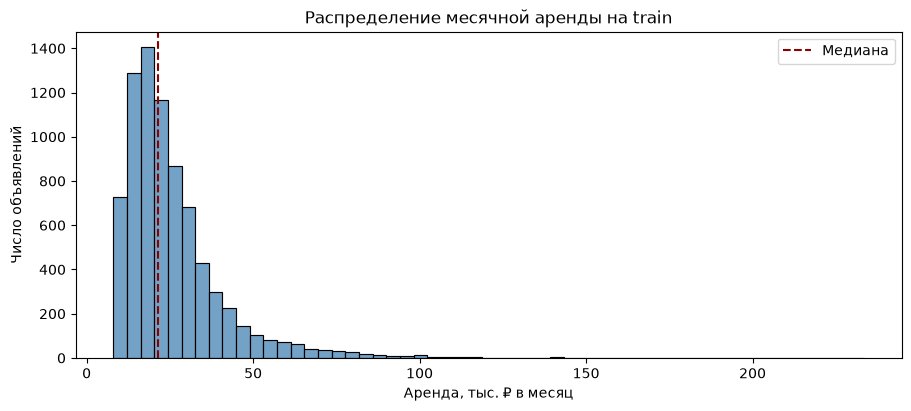

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

rent = audit[TARGET]
print(rent.describe().round().astype(int).to_string())

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
sns.histplot(x=rent / 1000, bins=55, ax=ax, color="steelblue")
ax.axvline(rent.median() / 1000, color="darkred", linestyle="--", label="Медиана")
ax.set(title="Распределение месячной аренды на train",
       xlabel="Аренда, тыс. ₽ в месяц", ylabel="Число объявлений")
ax.legend()
plt.show()

Медиана аренды – 21 500 ₽ в месяц. У половины объявлений цена лежит между 16 000 и 30 500 ₽. Дорогие квартиры образуют длинный правый хвост до 233 500 ₽ и поднимают среднее примерно до 25 739 ₽.

### Проверка выбросов и согласованности полей

По примеру практикума 2 вычисляем границы Тьюки для цены, общей площади и расстояния до метро. Границы находятся на расстоянии полутора межквартильных размахов от первого и третьего квартилей. Затем сверяем поля по смыслу.

In [10]:
features = audit[[TARGET, "total_area", "metro_distance_m"]]
q1 = features.quantile(0.25)
q3 = features.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

pd.DataFrame({
    "Нижняя граница": lower.round(1),
    "Верхняя граница": upper.round(1),
    "Ниже границы": features.lt(lower).sum(),
    "Выше границы": features.gt(upper).sum(),
})

,Нижняя граница,Верхняя граница,Ниже границы,Выше границы
rent_rub,-5750.0,52250.0,0,456
total_area,-3.8,102.6,0,296
metro_distance_m,-5270.0,10650.0,0,120


In [11]:
above_building = audit["floor"] > audit["floors_total"]
living_above_total = audit["living_area"] > audit["total_area"]
rooms_above_total = audit["living_area"] + audit["kitchen_area"] > audit["total_area"]
print("Этаж квартиры выше этажности дома –", above_building.sum())
print("Жилая площадь больше общей –", living_above_total.sum())
print("Сумма жилой и кухонной площадей больше общей –", rooms_above_total.sum())

audit.nlargest(5, "total_area")[["rooms", "total_area", "living_area", "kitchen_area", TARGET]]

Этаж квартиры выше этажности дома – 32
Жилая площадь больше общей – 20
Сумма жилой и кухонной площадей больше общей – 139


,rooms,total_area,living_area,kitchen_area,rent_rub
4164,4,936.0,46.1,6.8,25000
2967,4,877.0,50.0,10.3,49000
9631,3,858.0,48.9,10.9,26000
1789,3,853.0,52.3,8.1,32000
8185,3,846.0,39.8,11.2,36500


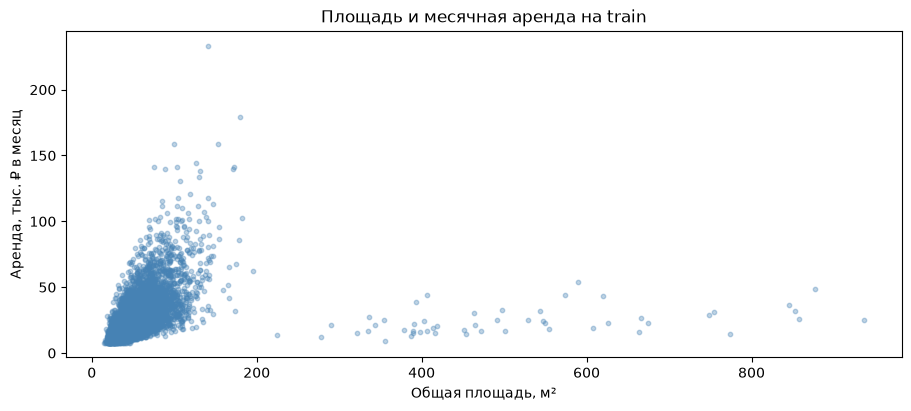

In [12]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.scatter(audit["total_area"], rent / 1000, s=10, alpha=0.35, color="steelblue")
ax.set(title="Площадь и месячная аренда на train",
       xlabel="Общая площадь, м²", ylabel="Аренда, тыс. ₽ в месяц")
plt.show()

При большой общей площади встречаются объявления с обычной ценой аренды. Например, у квартиры с общей площадью 936 м² указаны четыре комнаты, 46,1 м² жилой площади и цена 25 000 ₽. Возможна ошибка ввода общей площади. Для таких записей на этапе предобработки проверим согласованность полей. Исправление площади делением на десять требует подтверждения.

У 32 записей этаж выше этажности дома, у 20 жилая площадь превышает общую. Эти признаки потребуют обработки. Верхнюю границу IQR для цены (52 250 ₽) превысили 456 объявлений. Высокая цена сама по себе возможна, поэтому сохраняем эти объявления для моделирования.